# EUR/USD — 7-Day Forecast (Multi-Horizon Price)

Model: Ridge vs Linear Regression

Target: Close.shift(-1) s/d Close.shift(-7)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
PAIR = "EURUSD=X"
PAIR_NAME = "EUR/USD"
START_DATE = "2005-01-01"
HORIZONS = list(range(1, 8))

OUTPUT_DIR = Path("outputs_revisi")
OUTPUT_DIR.mkdir(exist_ok=True)

In [3]:
raw = yf.download(PAIR, start=START_DATE, progress=False, auto_adjust=False)

raw.columns = ['_'.join(col).strip() for col in raw.columns.values]
raw.columns = [c.replace(f'_{PAIR}', '') for c in raw.columns]

df = raw.reset_index().copy()
if 'Date_' in df.columns:
    df = df.rename(columns={'Date_': 'Date'})

if "Adj Close" in df.columns and "Close" not in df.columns:
    df = df.rename(columns={"Adj Close": "Close"})

needed_cols = ["Date", "Open", "High", "Low", "Close"]
missing = [c for c in needed_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Got: {list(df.columns)}")

df = df[needed_cols].dropna().copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Data: {len(df)} rows")
print(df.tail(3))

Data: 5571 rows
           Date      Open      High       Low     Close
5568 2026-06-23  1.142531  1.143903  1.137669  1.142714
5569 2026-06-24  1.137928  1.138433  1.132541  1.137954
5570 2026-06-25  1.136105  1.137398  1.134945  1.135847


In [4]:
def calculate_rsi(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi


def add_features(data):
    out = data.copy().sort_values("Date").reset_index(drop=True)

    out["return"] = out["Close"].pct_change()

    out["lag1"] = out["Close"].shift(1)
    out["lag7"] = out["Close"].shift(7)

    out["ma7"] = out["Close"].rolling(7).mean()
    out["ma21"] = out["Close"].rolling(21).mean()

    out["ma7_gap"] = (out["ma7"] - out["Close"]) / out["Close"]
    out["ma21_gap"] = (out["ma21"] - out["Close"]) / out["Close"]

    out["volatility7"] = out["return"].rolling(7).std()

    out["range_pct"] = (out["High"] - out["Low"]) / out["Close"]

    out["rsi14"] = calculate_rsi(out["Close"], 14)

    out["day_of_week"] = out["Date"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * out["day_of_week"] / 5)
    out["dow_cos"] = np.cos(2 * np.pi * out["day_of_week"] / 5)

    return out


feature_df = add_features(df)

FEATURES = [
    "Open", "High", "Low", "Close",
    "return", "lag1", "lag7",
    "ma7", "ma21",
    "ma7_gap", "ma21_gap",
    "volatility7", "range_pct",
    "rsi14",
    "dow_sin", "dow_cos"
]

print(f"Features: {len(FEATURES)}")
feature_df[["Date", "Close", "return", "ma7", "ma21", "rsi14"]].tail()

Features: 16


,Date,Close,return,ma7,ma21,rsi14
5566,2026-06-19,1.145856,-0.004240,1.155496,1.159086,25.552432
5567,2026-06-22,1.146276,0.000367,1.154455,1.158332,27.277888
5568,2026-06-23,1.142714,-0.003108,1.152329,1.157307,25.769891
5569,2026-06-24,1.137954,-0.004165,1.149136,1.156079,23.712330
5570,2026-06-25,1.135847,-0.001851,1.145768,1.154754,22.071853


In [5]:
for h in HORIZONS:
    feature_df[f"target_price_{h}d"] = feature_df["Close"].shift(-h)
    feature_df[f"target_date_{h}d"] = feature_df["Date"].shift(-h)

TARGET_COLS = [f"target_price_{h}d" for h in HORIZONS]

model_df = feature_df.dropna(subset=FEATURES + TARGET_COLS).copy()

X = model_df[FEATURES]
y = model_df[TARGET_COLS]

print(f"Train data: {len(model_df)} rows")
print(f"X shape: {X.shape}, y shape: {y.shape}")
model_df[["Date", "Close"] + TARGET_COLS].tail()

Train data: 5544 rows
X shape: (5544, 16), y shape: (5544, 7)


,Date,Close,target_price_1d,target_price_2d,target_price_3d,target_price_4d,target_price_5d,target_price_6d,target_price_7d
5559,2026-06-10,1.153536,1.153562,1.157595,1.160308,1.159420,1.160995,1.150735,1.145856
5560,2026-06-11,1.153562,1.157595,1.160308,1.159420,1.160995,1.150735,1.145856,1.146276
5561,2026-06-12,1.157595,1.160308,1.159420,1.160995,1.150735,1.145856,1.146276,1.142714
5562,2026-06-15,1.160308,1.159420,1.160995,1.150735,1.145856,1.146276,1.142714,1.137954
5563,2026-06-16,1.159420,1.160995,1.150735,1.145856,1.146276,1.142714,1.137954,1.135847


In [6]:
split_idx = int(len(model_df) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]
test_meta = model_df.iloc[split_idx:].copy()

print(f"Train: {model_df.iloc[0]['Date'].date()} s/d {model_df.iloc[split_idx-1]['Date'].date()} ({len(X_train)} rows)")
print(f"Test:  {model_df.iloc[split_idx]['Date'].date()} s/d {model_df.iloc[-1]['Date'].date()} ({len(X_test)} rows)")

Train: 2005-01-31 s/d 2022-03-09 (4435 rows)
Test:  2022-03-10 s/d 2026-06-16 (1109 rows)


In [7]:
ridge_default = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

linear = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

param_grid = {
    "ridge__alpha": np.logspace(-3, 3, 13),
    "ridge__fit_intercept": [True, False]
}

tscv = TimeSeriesSplit(n_splits=5)

grid = GridSearchCV(
    estimator=ridge_grid,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("Training models...")
ridge_default.fit(X_train, y_train)
grid.fit(X_train, y_train)
linear.fit(X_train, y_train)

ridge_best = grid.best_estimator_
print(f"Ridge best params: {grid.best_params_}")
print(f"Best CV MAE: {-grid.best_score_:.6f}")

Training models...
Ridge best params: {'ridge__alpha': np.float64(0.1), 'ridge__fit_intercept': True}
Best CV MAE: 0.011348


In [8]:
def evaluate_predictions(name, y_true_price, y_pred_price, current_close, horizons):
    rows = []
    for idx, h in enumerate(horizons):
        actual = y_true_price[:, idx]
        pred = y_pred_price[:, idx]

        mae = mean_absolute_error(actual, pred)
        rmse = np.sqrt(mean_squared_error(actual, pred))
        r2 = r2_score(actual, pred)

        mae_pips = mae * 10000

        future_ret = (actual - current_close) / current_close
        pred_ret = (pred - current_close) / current_close
        direction_acc = np.mean(np.sign(future_ret) == np.sign(pred_ret))

        within_5pip = np.abs(pred - actual) <= 0.0005
        hit_rate = np.mean(within_5pip)

        rows.append({
            "model": name,
            "horizon": h,
            "MAE_pips": round(mae_pips, 2),
            "R2": round(r2, 4),
            "direction_accuracy": round(direction_acc, 4),
            "hit_rate_5pip": round(hit_rate, 4)
        })
    return pd.DataFrame(rows)


current_close_test = test_meta["Close"].to_numpy()

pred_default = ridge_default.predict(X_test)
pred_best = ridge_best.predict(X_test)
pred_linear = linear.predict(X_test)
y_true = y_test.to_numpy()

eval_default = evaluate_predictions("Ridge (alpha=1)", y_true, pred_default, current_close_test, HORIZONS)
eval_best = evaluate_predictions("Ridge (grid search)", y_true, pred_best, current_close_test, HORIZONS)
eval_linear = evaluate_predictions("Linear Regression", y_true, pred_linear, current_close_test, HORIZONS)

eval_df = pd.concat([eval_default, eval_best, eval_linear], ignore_index=True)
eval_df

,model,horizon,MAE_pips,R2,direction_accuracy,hit_rate_5pip
0,Ridge (alpha=1),1,32.33,0.9927,0.6979,0.1208
1,Ridge (alpha=1),2,51.73,0.9821,0.6276,0.0658
2,Ridge (alpha=1),3,64.58,0.9721,0.6168,0.0523
3,Ridge (alpha=1),4,74.98,0.9624,0.5870,0.0433
4,Ridge (alpha=1),5,83.28,0.9532,0.5780,0.0523
5,Ridge (alpha=1),6,91.89,0.9435,0.5446,0.0343
6,Ridge (alpha=1),7,99.29,0.9347,0.5347,0.0379
7,Ridge (grid search),1,30.42,0.9935,0.7241,0.1064
8,Ridge (grid search),2,50.17,0.9831,0.6555,0.0658
9,Ridge (grid search),3,63.34,0.9732,0.6285,0.0460


In [9]:
summary = (
    eval_df
    .groupby("model")[["MAE_pips", "R2", "direction_accuracy", "hit_rate_5pip"]]
    .mean()
    .sort_values("MAE_pips")
)
print("=== Average Across All Horizons ===")
summary

=== Average Across All Horizons ===


,MAE_pips,R2,direction_accuracy,hit_rate_5pip
model,,,,
Ridge (grid search),70.132857,0.963871,0.618057,0.054243
Linear Regression,70.222857,0.963786,0.625543,0.054100
Ridge (alpha=1),71.154286,0.962957,0.598086,0.058100


In [10]:
best_model_name = summary.index[0]
best_model = {
    "Ridge (alpha=1)": ridge_default,
    "Ridge (grid search)": ridge_best,
    "Linear Regression": linear
}[best_model_name]
print(f"Best model: {best_model_name}")

Best model: Ridge (grid search)


## Predicted vs Actual (Horizon 7)

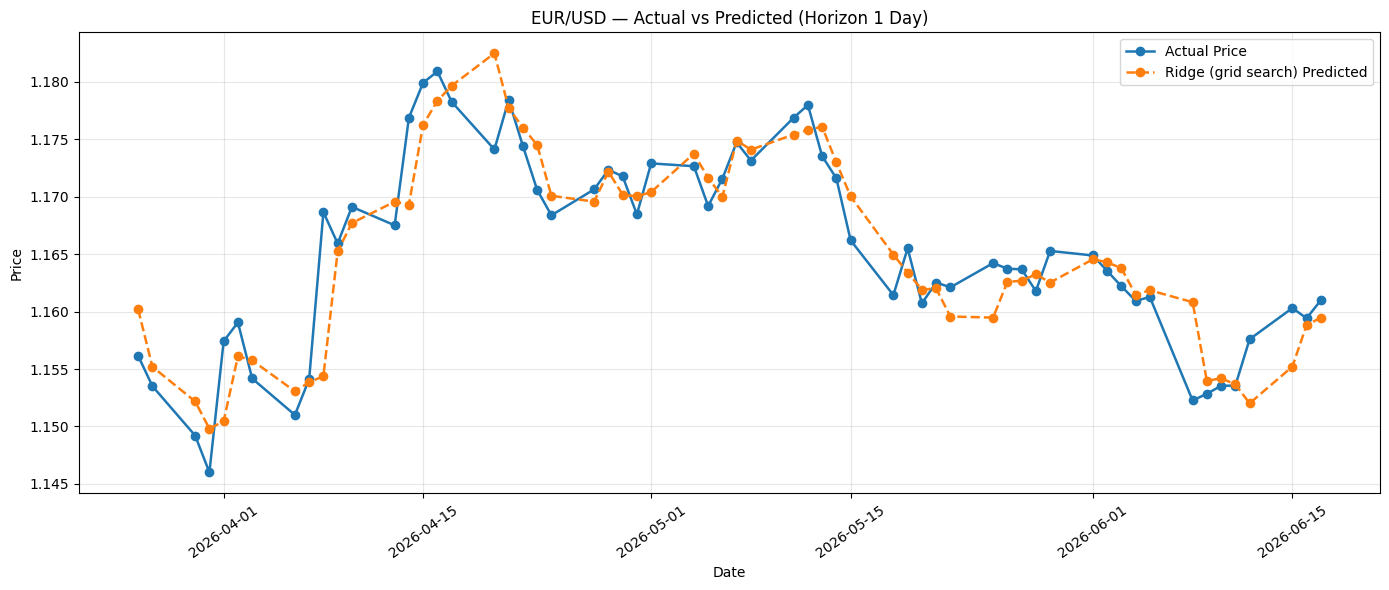

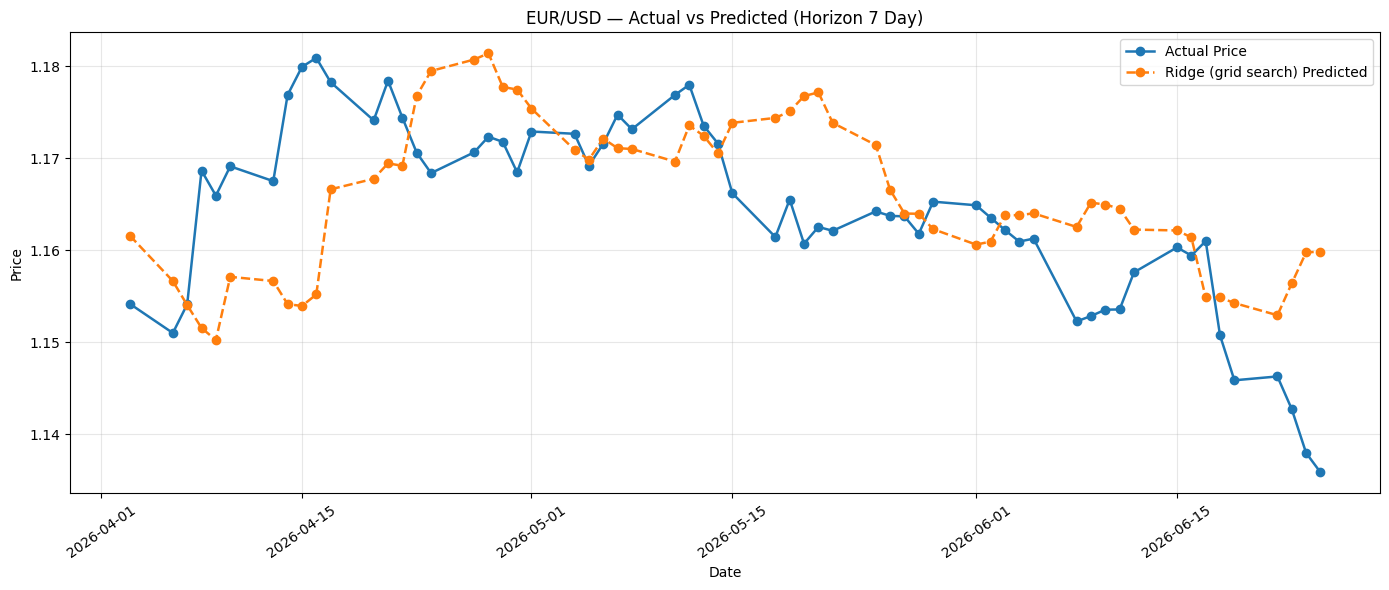

In [11]:
def plot_actual_vs_predicted(horizon=7, last_n=60):
    h_idx = HORIZONS.index(horizon)
    
    actual_h = y_test.to_numpy()[:, h_idx]
    pred_h = best_model.predict(X_test)[:, h_idx]

    plot_dates = pd.to_datetime(test_meta[f"target_date_{horizon}d"])

    plot_df = pd.DataFrame({
        "Date": plot_dates,
        "Actual": actual_h,
        "Predicted": pred_h
    }).dropna().tail(last_n)

    plt.figure(figsize=(14, 6))
    plt.plot(plot_df["Date"], plot_df["Actual"], marker="o", linewidth=1.8, label="Actual Price")
    plt.plot(plot_df["Date"], plot_df["Predicted"], marker="o", linestyle="--", linewidth=1.8, label=f"{best_model_name} Predicted")
    plt.title(f"{PAIR_NAME} — Actual vs Predicted (Horizon {horizon} Day)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# Plot horizon 1 dan 7
plot_actual_vs_predicted(horizon=1, last_n=60)
plot_actual_vs_predicted(horizon=7, last_n=60)

In [12]:
final_model = clone(best_model)
final_model.fit(X, y)

model_bundle = {
    "model": final_model,
    "features": FEATURES,
    "horizons": HORIZONS,
    "target_type": "multi_horizon_price",
    "pair": PAIR,
    "pair_name": PAIR_NAME,
    "best_params": getattr(grid, 'best_params_', {}),
    "model_name": best_model_name
}

model_path = OUTPUT_DIR / f"ridge_{PAIR_NAME.replace('/', '').lower()}_multihorizon.pkl"
features_path = OUTPUT_DIR / f"features_{PAIR_NAME.replace('/', '').lower()}.json"

joblib.dump(model_bundle, model_path)
with open(features_path, "w") as f:
    json.dump(FEATURES, f)

print(f"Model saved: {model_path}")
print(f"Features saved: {features_path}")

Model saved: outputs_revisi\ridge_eurusd_multihorizon.pkl
Features saved: outputs_revisi\features_eurusd.json


In [13]:
latest_row = feature_df.dropna(subset=FEATURES).iloc[-1:].copy()
latest_X = latest_row[FEATURES]

latest_date = pd.to_datetime(latest_row["Date"].iloc[0])
latest_close = float(latest_row["Close"].iloc[0])

forecast_prices = final_model.predict(latest_X)[0]

future_dates = pd.bdate_range(latest_date + pd.offsets.BDay(1), periods=len(HORIZONS))

forecast_df = pd.DataFrame({
    "horizon": HORIZONS,
    "date": future_dates,
    "forecast_price": forecast_prices
})
forecast_df["last_close"] = latest_close
forecast_df["last_date"] = latest_date.strftime("%Y-%m-%d")
forecast_df["change_from_close"] = ((forecast_df["forecast_price"] / latest_close) - 1) * 100

forecast_df

,horizon,date,forecast_price,last_close,last_date,change_from_close
0,1,2026-06-26,1.134007,1.135847,2026-06-25,-0.162036
1,2,2026-06-29,1.133920,1.135847,2026-06-25,-0.169688
2,3,2026-06-30,1.134500,1.135847,2026-06-25,-0.118589
3,4,2026-07-01,1.134977,1.135847,2026-06-25,-0.076659
4,5,2026-07-02,1.135256,1.135847,2026-06-25,-0.052041
5,6,2026-07-03,1.135155,1.135847,2026-06-25,-0.060994
6,7,2026-07-06,1.135196,1.135847,2026-06-25,-0.057380


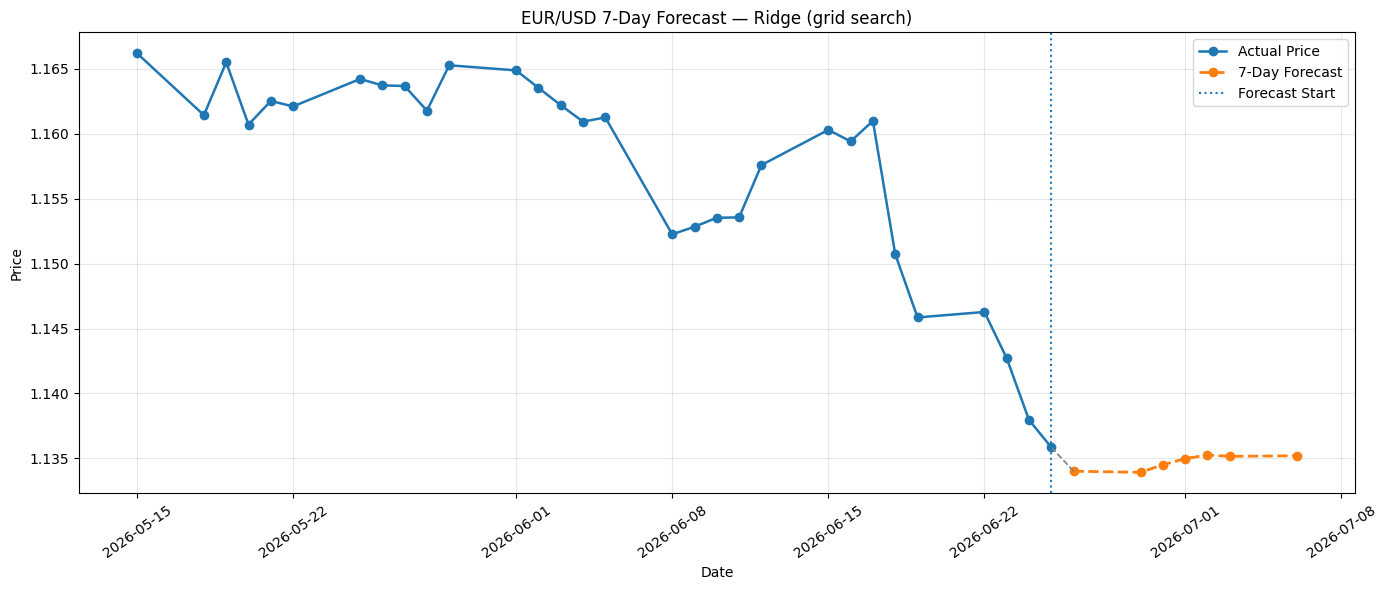

Last close: 1.13585
Forecast day 7: 1.13520
Expected change: -0.0574%


In [14]:
history_plot = feature_df.dropna(subset=["Close"]).tail(30)[["Date", "Close"]].copy()

plt.figure(figsize=(14, 6))
plt.plot(history_plot["Date"], history_plot["Close"], marker="o", linewidth=1.8, label="Actual Price")
plt.plot(forecast_df["date"], forecast_df["forecast_price"], marker="o", linestyle="--", linewidth=2.0, label="7-Day Forecast")

plt.plot(
    [history_plot["Date"].iloc[-1], forecast_df["date"].iloc[0]],
    [history_plot["Close"].iloc[-1], forecast_df["forecast_price"].iloc[0]],
    linestyle="--", linewidth=1.2, color="gray"
)

plt.axvline(history_plot["Date"].iloc[-1], linestyle=":", linewidth=1.5, label="Forecast Start")
plt.title(f"{PAIR_NAME} 7-Day Forecast — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print(f"Last close: {latest_close:.5f}")
print(f"Forecast day 7: {forecast_df['forecast_price'].iloc[-1]:.5f}")
print(f"Expected change: {forecast_df['change_from_close'].iloc[-1]:+.4f}%")

In [15]:
eval_df.to_csv(OUTPUT_DIR / f"metrics_{PAIR_NAME.replace('/', '').lower()}.csv", index=False)
print(f"\nAll files saved to: {OUTPUT_DIR}/")


All files saved to: outputs_revisi/
